# ENGR 140 case study: buy a dilution refrigerator or rent cloud qubits?

An engineering-economics problem built on the quantum-hardware thread (`cryo_qubit_readout.ipynb`).
Every tool here is standard ENGR 140 material: interest factors, cash-flow diagrams, NPV,
equivalent annual cost (EAC), break-even, depreciation, and sensitivity analysis.
Module: `dgs/engr_economics.py` (tests: `tests/test_engr_economics.py`).

**Every dollar figure below is an ASSUMPTION** (order-of-magnitude, from public price
discussions as of 2024), and each one is a variable you can change. The *method* is the point.

In [1]:
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import sympy as sp
sp.init_printing(use_unicode=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from dgs import engr_economics as E
pd.set_option("display.width", 200)

# ---- ASSUMPTIONS (edit these) ------------------------------------------------------------
FIRST_COST = 1_000_000      # $: fridge (~$0.6M) + wiring, amplifiers, control electronics (~$0.4M)
ANNUAL_OPS = 60_000         # $/yr: power, cooling water, service contract, consumables
SALVAGE = 100_000           # $ resale at end of life
LIFE_YR = 10                # years
MARR = 0.08                 # minimum attractive rate of return
CLOUD_PER_HOUR = 96 * 60    # $/QPU-hour: pay-as-you-go list price ~$96/min (2024); check current
display(pd.DataFrame({"assumption": ["first cost", "annual operating", "salvage", "life", "MARR", "cloud $/QPU-hour"],
                      "value": [FIRST_COST, ANNUAL_OPS, SALVAGE, LIFE_YR, MARR, CLOUD_PER_HOUR]}))

,assumption,value
0,first cost,1000000.00
1,annual operating,60000.00
2,salvage,100000.00
3,life,10.00
4,MARR,0.08
5,cloud $/QPU-hour,5760.00


**Apples-to-oranges warning (state this in any write-up).** "Own" here buys a cold, wired
fridge. It still needs a qubit chip, staff, and months of setup, none of which is counted.
"Rent" buys time on a working 100+ qubit processor. On the other hand, a fridge runs 24/7 and
does more than execute circuits: device research, sensors, materials. So the comparison
answers one narrow question: **at what yearly usage does owning the cryostat stop being
the more expensive way to get qubit time?**

## 1. Where the factors come from (SymPy)

**Quantity:** P, the present worth of a uniform payment A at the end of each of n years.
**Equation:** P = Σₜ₌₁ⁿ A(1+i)⁻ᵗ, a geometric series. **Isolated:** P = A·(P/A, i, n), and
A = P·(A/P, i, n). **Units:** factors are dimensionless, $ in gives $ out.
**Meaning:** (A/P) turns a purchase into "rent you pay yourself" every year.

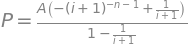

equals the textbook closed form? True


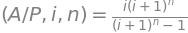

,"factor (i=10%, n=5)",value
0,P/F,0.62092
1,P/A,3.79079
2,A/P,0.26380
3,F/A,6.10510
4,A/F,0.16380


check against an interest table: P/A = 3.7908, A/P = 0.26380


In [2]:
i, n, t, A, P = sp.symbols("i n t A P", positive=True)
series = sp.summation(A * (1 + i)**-t, (t, 1, n))
closed = A * ((1 + i)**n - 1) / (i * (1 + i)**n)
display(sp.Eq(sp.Symbol("P"), series))
print("equals the textbook closed form?", sp.simplify(sp.piecewise_fold(series).args[-1][0] - closed) == 0
      if isinstance(series, sp.Piecewise) else sp.simplify(series - closed) == 0)
display(sp.Eq(sp.Symbol("(P/A,i,n)"), closed / A))
display(sp.Eq(sp.Symbol("(A/P,i,n)"), sp.simplify(A / closed)))

table = pd.DataFrame([(name, f(0.10, 5)) for name, f in [("P/F", E.p_given_f), ("P/A", E.p_given_a),
                       ("A/P", E.a_given_p), ("F/A", E.f_given_a), ("A/F", E.a_given_f)]],
                     columns=["factor (i=10%, n=5)", "value"])
display(table.round(5))
print("check against an interest table: P/A = 3.7908, A/P = 0.26380")

## 2. Cash-flow diagram for owning

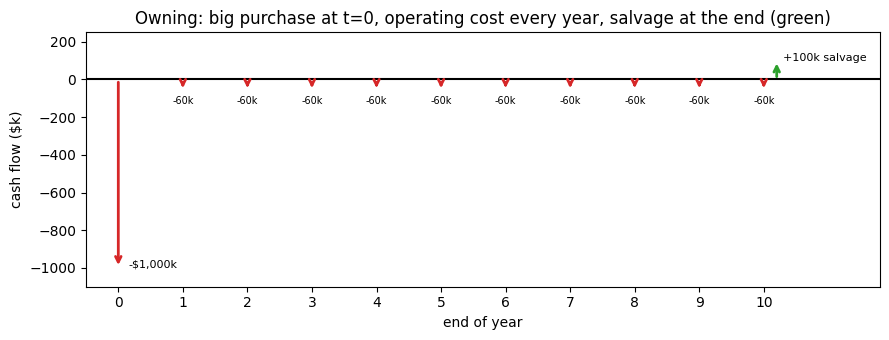

present worth of owning at MARR = 8%: $-1,356,286


In [3]:
flows = [-FIRST_COST] + [-ANNUAL_OPS] * (LIFE_YR - 1) + [-ANNUAL_OPS + SALVAGE]
fig, ax = plt.subplots(figsize=(9, 3.5))
arrow = lambda x0, y, c: ax.annotate("", xy=(x0, y), xytext=(x0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2))
arrow(0, -FIRST_COST / 1e3, "C3"); ax.text(0.15, -FIRST_COST / 1e3, f"-${FIRST_COST / 1e3:,.0f}k", fontsize=8)
for yr in range(1, LIFE_YR + 1):
    arrow(yr, -ANNUAL_OPS / 1e3, "C3"); ax.text(yr, -ANNUAL_OPS / 1e3 - 70, f"-{ANNUAL_OPS / 1e3:.0f}k", fontsize=7, ha="center")
arrow(LIFE_YR + 0.2, SALVAGE / 1e3, "C2"); ax.text(LIFE_YR + 0.3, SALVAGE / 1e3, f"+{SALVAGE / 1e3:.0f}k salvage", fontsize=8)
ax.axhline(0, color="k"); ax.set_xticks(range(LIFE_YR + 1)); ax.set_xlabel("end of year")
ax.set_ylabel("cash flow ($k)"); ax.set_ylim(-FIRST_COST / 1e3 * 1.1, SALVAGE / 1e3 * 2.5); ax.set_xlim(-0.5, LIFE_YR + 1.8)
ax.set_title("Owning: big purchase at t=0, operating cost every year, salvage at the end (green)")
plt.tight_layout(); plt.show()
pw = E.npv(flows, MARR)
print(f"present worth of owning at MARR = {MARR:.0%}: ${pw:,.0f}")

## 3. Equivalent annual cost and break-even

EAC = P·(A/P) + annual cost − S·(A/F). Renting costs (cloud rate) × (hours per year).
Set them equal and solve for hours: that is the **break-even usage**.

EAC of owning   = $202,127 per year
  capital recovery P(A/P) = $149,029
  operating               = $60,000
  salvage credit S(A/F)   = -$6,903
break-even usage = 35.1 QPU-hours per year (~40 minutes per week)
check: EAC as present worth = $1,356,286 vs NPV of flows $1,356,286


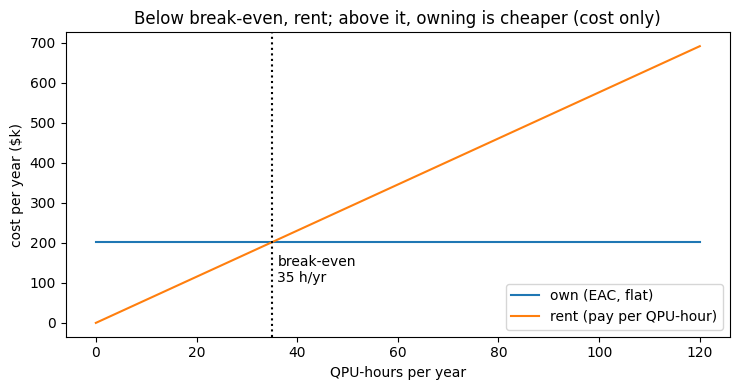

In [4]:
eac = E.equivalent_annual_cost(FIRST_COST, ANNUAL_OPS, SALVAGE, MARR, LIFE_YR)
h_be = E.breakeven_usage(eac, CLOUD_PER_HOUR)
print(f"EAC of owning   = ${eac:,.0f} per year")
print(f"  capital recovery P(A/P) = ${FIRST_COST * E.a_given_p(MARR, LIFE_YR):,.0f}")
print(f"  operating               = ${ANNUAL_OPS:,.0f}")
print(f"  salvage credit S(A/F)   = -${SALVAGE * E.a_given_f(MARR, LIFE_YR):,.0f}")
print(f"break-even usage = {h_be:.1f} QPU-hours per year (~{h_be * 60 / 52:.0f} minutes per week)")
print("check: EAC as present worth =", f"${eac * E.p_given_a(MARR, LIFE_YR):,.0f}", "vs NPV of flows", f"${-pw:,.0f}")

hours = np.linspace(0, 120, 300)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(hours, np.full_like(hours, eac / 1e3), label="own (EAC, flat)")
ax.plot(hours, CLOUD_PER_HOUR * hours / 1e3, label="rent (pay per QPU-hour)")
ax.axvline(h_be, color="k", ls=":"); ax.text(h_be + 1, eac / 1e3 * 0.5, f"break-even\n{h_be:.0f} h/yr")
ax.set_xlabel("QPU-hours per year"); ax.set_ylabel("cost per year ($k)"); ax.legend()
ax.set_title("Below break-even, rent; above it, owning is cheaper (cost only)")
plt.tight_layout(); plt.show()

## 4. Sensitivity: which assumption matters most?

Vary each input ±50% (MARR from 4% to 12%) while holding the others fixed, and see how the
break-even moves. The longest bar is the assumption worth researching first. This is the
tornado diagram from ENGR 140.

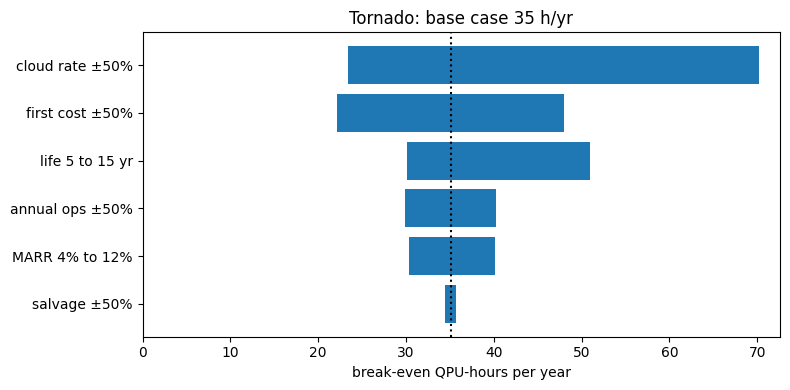

,low,high
first cost ±50%,22.2,48.0
annual ops ±50%,29.9,40.3
salvage ±50%,34.5,35.7
MARR 4% to 12%,30.4,40.2
life 5 to 15 yr,30.1,50.9
cloud rate ±50%,23.4,70.2


In [5]:
def be(first=FIRST_COST, ops=ANNUAL_OPS, salv=SALVAGE, marr=MARR, life=LIFE_YR, rate=CLOUD_PER_HOUR):
    return E.breakeven_usage(E.equivalent_annual_cost(first, ops, salv, marr, life), rate)

base = be()
cases = {"first cost ±50%": (be(first=FIRST_COST * 0.5), be(first=FIRST_COST * 1.5)),
         "annual ops ±50%": (be(ops=ANNUAL_OPS * 0.5), be(ops=ANNUAL_OPS * 1.5)),
         "salvage ±50%": (be(salv=SALVAGE * 1.5), be(salv=SALVAGE * 0.5)),
         "MARR 4% to 12%": (be(marr=0.04), be(marr=0.12)),
         "life 5 to 15 yr": (be(life=15), be(life=5)),
         "cloud rate ±50%": (be(rate=CLOUD_PER_HOUR * 1.5), be(rate=CLOUD_PER_HOUR * 0.5))}
order = sorted(cases, key=lambda k: abs(cases[k][1] - cases[k][0]))
fig, ax = plt.subplots(figsize=(8, 4))
for y, k in enumerate(order):
    lo, hi = cases[k]
    ax.barh(y, hi - lo, left=lo, color="C0")
ax.axvline(base, color="k", ls=":"); ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.set_xlim(0, None)
ax.set_xlabel("break-even QPU-hours per year"); ax.set_title(f"Tornado: base case {base:.0f} h/yr")
plt.tight_layout(); plt.show()
display(pd.DataFrame(cases, index=["low", "high"]).T.round(1))

## 5. Depreciation (for the tax / book-value side)

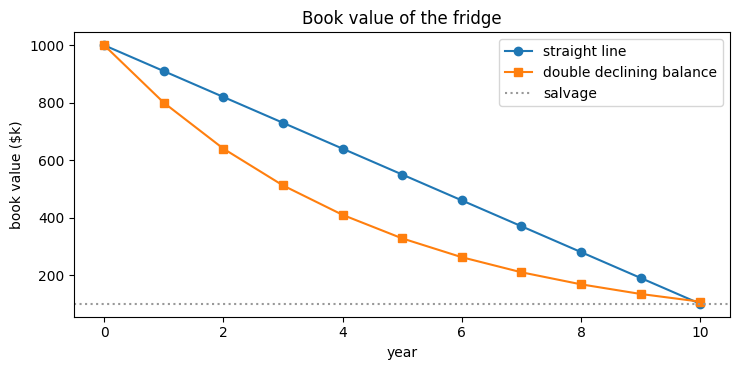

In [6]:
sl = E.straight_line(FIRST_COST, SALVAGE, LIFE_YR)
ddb = E.declining_balance(FIRST_COST, LIFE_YR, factor=2.0, salvage=SALVAGE)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot([0] + [r[0] for r in sl], [FIRST_COST / 1e3] + [r[2] / 1e3 for r in sl], "o-", label="straight line")
ax.plot([0] + [r[0] for r in ddb], [FIRST_COST / 1e3] + [r[2] / 1e3 for r in ddb], "s-", label="double declining balance")
ax.axhline(SALVAGE / 1e3, color="0.6", ls=":", label="salvage")
ax.set_xlabel("year"); ax.set_ylabel("book value ($k)"); ax.legend(); ax.set_title("Book value of the fridge")
plt.tight_layout(); plt.show()

## Practice (my own problems)

1. A $50,000 oscilloscope lasts 5 years with $5,000 salvage. At 10%, what is its capital-recovery cost per year?
2. A project costs $1,000 now and returns $500 and $600 at the ends of years 1 and 2. Find the NPV at 10% and the IRR.
3. If the cloud price dropped to $1.00 per second, what would the break-even become (other assumptions unchanged)?
4. Can $60,000 per year of operating cost ever add up to the $1M first cost in present worth at 8%? (Hint: what does (P/A, i, n) tend to as n → ∞?)

In [7]:
print(f"1. ${E.equivalent_annual_cost(50_000, 0, 5_000, 0.10, 5):,.0f} per year")
print(f"2. NPV = ${E.npv([-1000, 500, 600], 0.10):,.2f},  IRR = {E.irr([-1000, 500, 600]):.2%}")
print(f"3. {be(rate=3600):.1f} QPU-hours per year")
print(f"4. No. (P/A, i, n) -> 1/i as n -> infinity (a perpetuity), so the most it can be worth is "
      f"60,000 / 0.08 = ${60_000 / 0.08:,.0f};  after 100 years: ${60_000 * E.p_given_a(0.08, 100):,.0f}")
print("   SymPy limit:", sp.limit(((1 + i)**n - 1) / (i * (1 + i)**n), n, sp.oo))

1. $12,371 per year
2. NPV = $-49.59,  IRR = 6.39%
3. 56.1 QPU-hours per year
4. No. (P/A, i, n) -> 1/i as n -> infinity (a perpetuity), so the most it can be worth is 60,000 / 0.08 = $750,000;  after 100 years: $749,659
   SymPy limit: 1/i


## Checklist

- [ ] Draw the cash-flow diagram before touching a formula.
- [ ] (P/A) is a geometric series. (A/P) = 1/(P/A). (A/P) = (A/F) + i.
- [ ] Compare alternatives on the same basis: present worth, or EAC per year.
- [ ] Break-even = EAC ÷ (rent rate − own variable cost).
- [ ] Run a tornado chart and spend your research time on the longest bar.
- [ ] State what the comparison leaves out (chip, staff, setup time, non-circuit uses of the fridge).